<a href="https://colab.research.google.com/github/francescaarrusm/5685052---DataScience-GenAI-Submissions/blob/main/seminar_week3_titanic_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Understanding the Data

To read the CSV gile using the **pandas** library and store its data inside a tabular variable (**DataFrame**) named **"titanic"**...


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from google.colab import files
upload = files.upload()

Saving titanic.csv to titanic.csv


To display the first 5 rows of that dataset to preview the columns and variables:

**variable = pd.read_csv ('file name')**

**variable.head ()**

In [3]:
titanic = pd.read_csv('titanic.csv')
titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


To find the number of rows and columns: **".shape"**

1.   Elemento de lista
2.   Elemento de lista



In [4]:
titanic.shape

(891, 12)

To get information about the data: **".info"**


In [5]:
titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


To interpret this data:

*   **'non-null'** meaning how many actual valid values exist in each column
*   **'Object'** meaning text/string
*   **'int64'** meaning integers
*   **'float64'** meaning numbers with decimal points

To verify whether there is missing data: **".isnull().sum()"**

In [6]:
titanic.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In order to work with missing data, we may consider deleting some columns - to see the percentage of the column's data that is missing:

**"# Percent of data which is not available // .isnull().sum()/len([data name]) * 100"**

In [7]:
# Percent of data which is not available
titanic.isnull().sum()/len(titanic)*100

,0
PassengerId,0.000000
Survived,0.000000
Pclass,0.000000
Name,0.000000
Sex,0.000000
Age,19.865320
SibSp,0.000000
Parch,0.000000
Ticket,0.000000
Fare,0.000000


To find unique or duplicated rows: **".duplicated().value_counts()"**

In [8]:
titanic.duplicated().value_counts()

,count
False,891


*This means no duplicates (there are 891 rows)

To get summary statistics of the data: **".describe()"**

*Applies only to numeric data

In [9]:
titanic.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


# Visualising the Data

*Note that I made a mistake in how I initially inputed the code to graph the data: **"plt.bar()"** overlaps the bars on top of each other, so the tallest bar (1 for the survivors) hides everything underneath, making every class bar look like it reaches exactly 1.

[]

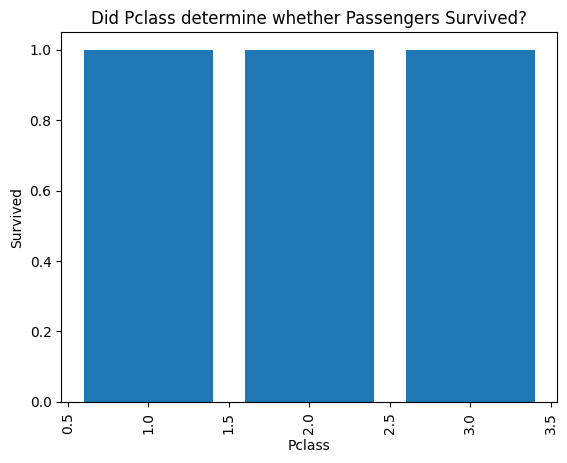

In [13]:
plt.bar(titanic['Pclass'], titanic['Survived']) # create a bar chart of the two values
# note we use a "\" symbol so that the apostrophy doesn't close the string
plt.xlabel('Pclass') # x-axis is Pclass of the Passengers
plt.xticks(rotation=90) # rotate x labels 90 degrees (vertical)
plt.ylabel('Survived') # y-axis is whether the Passengers survived
plt.title('Did Pclass determine whether Passengers Survived?') # add title
plt.plot() # plot the chart to screen

In this case, we need to calculate **average (mean) survival rate** for each **`Pclass`** first, or let a library (e.g **seaborn**) do the aggregation for us.

#### 1. Using Seaborn (Auto-Aggregation)
`sns.barplot` automatically calculates the average (mean) of the y-variable (`Survived`) for each category on the x-axis (`Pclass`) and displays error bars.

*Note that `ci` stands for **Confidence Interval** which represents the range of values around the estimate, otherwise, an **error bar**.

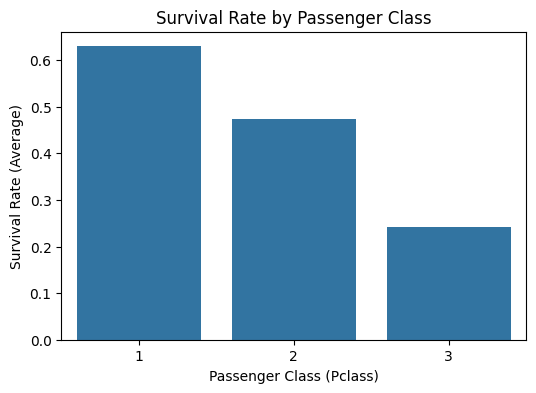

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
sns.barplot(x='Pclass', y='Survived', data=titanic, errorbar=None)

plt.xlabel('Passenger Class (Pclass)')
plt.ylabel('Survival Rate (Average)')
plt.title('Survival Rate by Passenger Class')
plt.show()

#### 2. Using Matplotlib (Manual Aggregation)
Here, we manually group the data by `Pclass` and calculate the average survival rate before plotting.

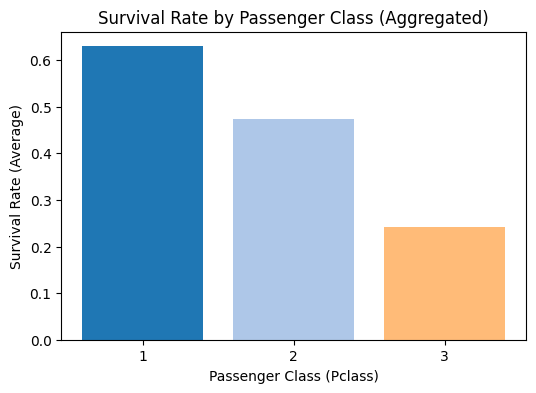

In [16]:
# Calculate average survival rate for each class
class_survival = titanic.groupby('Pclass')['Survived'].mean()

plt.figure(figsize=(6, 4))
plt.bar(class_survival.index.astype(str), class_survival.values, color=['#1f77b4', '#aec7e8', '#ffbb78'])

plt.xlabel('Passenger Class (Pclass)')
plt.ylabel('Survival Rate (Average)')
plt.title('Survival Rate by Passenger Class (Aggregated)')
plt.show()

From this **data visualisation**, we can conclude there is a corelation:

Those passengers in `Pclass` `1` had a greater chance of having `Survived` than those in the other `Pclass`' (`2` and `3`)

Another data visualisation can look like:


[]

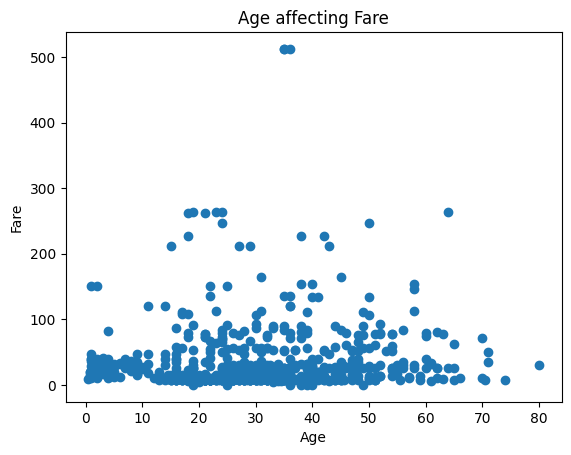

In [17]:
plt.scatter(titanic['Age'], titanic['Fare'])
plt.xlabel('Age')
plt.ylabel('Fare')
plt.title('Age affecting Fare')
plt.plot()

#### Improving the Visualisation with Seaborn Joint Plots
A joint plot allows us to see both the scatter plot of two variables and their individual distributions (histograms) on the margins. We will filter the `Fare` column to look at passengers who paid < 150.



1.   First, define the data for  fares < 150:
**""titanic_under_150 = titanic[titanic['Fare']<150""**
2.  Now, create the scatter plot:

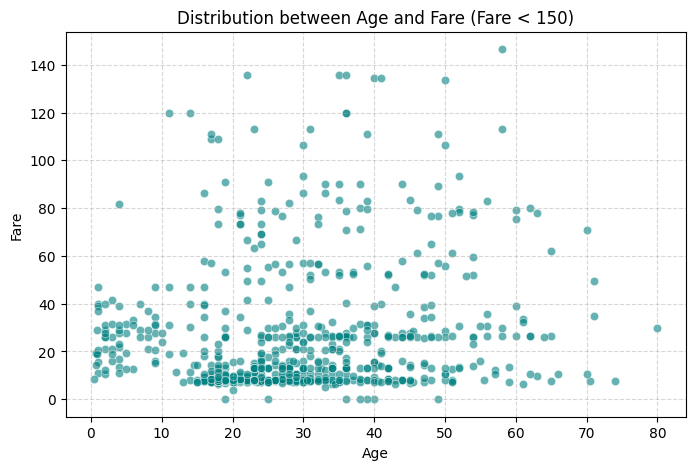

In [23]:
titanic_under_150 = titanic[titanic['Fare'] < 150]

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=titanic_under_150,
    x='Age',
    y='Fare',
    alpha=0.6,
    color='teal'
)
plt.title('Distribution between Age and Fare (Fare < 150)')
plt.xlabel('Age')
plt.ylabel('Fare')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

From this visualisation, we can see that there is no corelation between `Age` and `Fare`, though we can see that most `Fares` cost under 40.

To see if a variable (e.g `Age`) follows a [normal distribution](https://en.wikipedia.org/wiki/Normal_distribution):

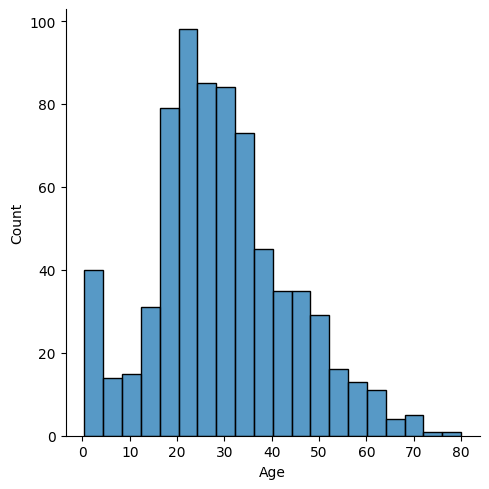

In [24]:
ax = sns.displot(titanic['Age'])

From this visualisation, we can see that most `Passengers` are `Aged` between 20 and 35.

We can use the _pairplot( )_ method to visualise pairs of variables:

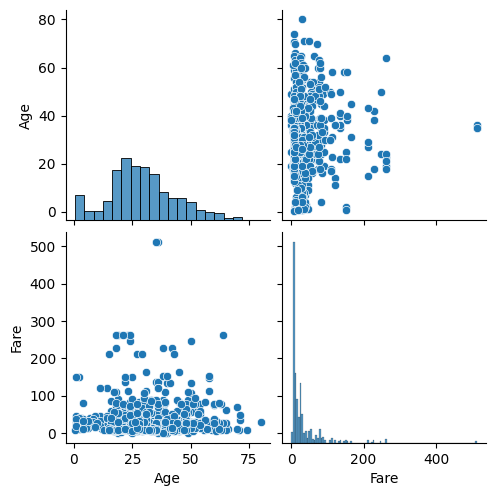

In [29]:
sns.pairplot(data = titanic[['Age','Fare']],diag_kind='hist')

We can also decide to remove a variable if its not relevant:

In [42]:
titanic = titanic.drop(['PassengerId', 'SibSp', 'Parch', 'Ticket', 'Cabin'], axis=1, errors='ignore')
titanic.head()

,Survived,Pclass,Sex,Fare,Embarked
0,0,3,male,7.2500,S
1,1,1,female,71.2833,C
2,1,3,female,7.9250,S
3,1,1,female,53.1000,S
4,0,3,male,8.0500,S
